# Pandas

The `numpy` module is excellent for numerical computations, but to handle missing data or arrays with mixed types takes more work. The `pandas` module is currently the most widely used tool for data manipulation, providing high-performance, easy-to-use data structures and advanced data analysis tools.

In particular `pandas` features:

* A fast and efficient "DataFrame" object for data manipulation with integrated indexing;
* Tools for reading and writing data between in-memory data structures and different formats (CSV, Excel, SQL, HDF5);
* Intelligent data alignment and integrated handling of missing data;
* Intelligent label-based slicing, fancy indexing, and subsetting of large data sets;
* Aggregating or transforming data with a powerful "group-by" engine; 
* High performance merging and joining of data sets;
* Hierarchical axis indexing provides an intuitive way of working with high-dimensional data in a lower-dimensional data structure;
* Time series-functionalities;
* Highly optimized for performance, with critical code paths written in Cython or C.


In [122]:
import pandas as pd
import numpy as np

## Series

Series are completely equivalent to 1D array but with axis labels and the possibility to store heterogeneous elements. Of paramount importance are the time-series, used to define time evolutions of a phenomenon. 


In [123]:
from string import ascii_lowercase as letters

# Creating a series, accessing indexes, values and values by their index 
xs = pd.Series(np.arange(10)*0.5, index=tuple(letters[:10]))
print ("xs:", xs,'\n')
print ("xs indexes:",xs.index,'\n')
# Values of the Series are actually a numpy array
print ("xs values:", xs.values, type(xs.values),'\n')
print (xs['f'], xs.f, xs.h, '\n')
print (xs[['d', 'f', 'h']], '\n')
print (type(xs[['d', 'f', 'h']]), '\n')

xs: a    0.0
b    0.5
c    1.0
d    1.5
e    2.0
f    2.5
g    3.0
h    3.5
i    4.0
j    4.5
dtype: float64 

xs indexes: Index(['a', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'i', 'j'], dtype='object') 

xs values: [0.  0.5 1.  1.5 2.  2.5 3.  3.5 4.  4.5] <class 'numpy.ndarray'> 

2.5 2.5 3.5 

d    1.5
f    2.5
h    3.5
dtype: float64 

<class 'pandas.core.series.Series'> 



In [124]:
# Extracting elements and operations: same as numpy array
print (xs[:3],'\n')
print (xs[7:], '\n')
print (xs[::3], '\n')
print (xs[xs>3], '\n')
print (np.exp(xs), '\n')
print (np.mean(xs), np.std(xs), '\n')

a    0.0
b    0.5
c    1.0
dtype: float64 

h    3.5
i    4.0
j    4.5
dtype: float64 

a    0.0
d    1.5
g    3.0
j    4.5
dtype: float64 

h    3.5
i    4.0
j    4.5
dtype: float64 

a     1.000000
b     1.648721
c     2.718282
d     4.481689
e     7.389056
f    12.182494
g    20.085537
h    33.115452
i    54.598150
j    90.017131
dtype: float64 

2.25 1.4361406616345072 



In [125]:
# Series can be created from python dictionary too.
# Not that the elements can be whatever!
d = {'b' : 1, 'a' : 'cat', 'c' : [2,3]}
pd.Series(d)



b         1
a       cat
c    [2, 3]
dtype: object

A key difference between Series and ndarray is that operations between Series automatically align the data based on label. Thus, you can write computations without considering whether the Series involved have the same labels.

In [126]:
s = pd.Series(np.random.randn(5), index=tuple(letters[:5]))
print(s)
s = s[1:] + s[:-1]
print(s)

a   -0.492074
b   -1.130379
c    0.126176
d   -0.373277
e    0.905974
dtype: float64
a         NaN
b   -2.260759
c    0.252351
d   -0.746554
e         NaN
dtype: float64


### Time series

Time series are very often used to profile the behaviour of a quantity as a function of time. Pandas has a special index for that, `DatetimeIndex`, that can be created e.g. with the function `pd.data_range()`

In [127]:
# to define a date, the datetime module is very useful
import datetime as dt
date = dt.date.today()
print(date)

date = dt.datetime(2026,11,18,10,45,10,15)
print (date)

# otherwise, several notations are interpreted too
date = 'Nov 18 2026'
# or alternatively
#date = '18/11/2026 10:45:00'
print (date)

days = pd.date_range(date, periods=7, freq='D')
print (days)

seconds = pd.date_range(date, periods=3600, freq='s')
print (seconds)


2026-11-18
2026-11-18 10:45:10.000015
Nov 18 2026
DatetimeIndex(['2026-11-18', '2026-11-19', '2026-11-20', '2026-11-21',
               '2026-11-22', '2026-11-23', '2026-11-24'],
              dtype='datetime64[ns]', freq='D')
DatetimeIndex(['2026-11-18 00:00:00', '2026-11-18 00:00:01',
               '2026-11-18 00:00:02', '2026-11-18 00:00:03',
               '2026-11-18 00:00:04', '2026-11-18 00:00:05',
               '2026-11-18 00:00:06', '2026-11-18 00:00:07',
               '2026-11-18 00:00:08', '2026-11-18 00:00:09',
               ...
               '2026-11-18 00:59:50', '2026-11-18 00:59:51',
               '2026-11-18 00:59:52', '2026-11-18 00:59:53',
               '2026-11-18 00:59:54', '2026-11-18 00:59:55',
               '2026-11-18 00:59:56', '2026-11-18 00:59:57',
               '2026-11-18 00:59:58', '2026-11-18 00:59:59'],
              dtype='datetime64[ns]', length=3600, freq='S')


To learn more about the frequency strings, please see this [link](http://pandas.pydata.org/pandas-docs/stable/timeseries.html#offset-aliases)


Timestamped data is the most basic type of time series data that associates values with points in time. For pandas objects it means using the points in time.

functions like `pd.to_datetime` can be used, for instance, when reading information as string from a dataset.

Timestamp is the pandas equivalent of python’s Datetime and is interchangeable with it in most cases. 

In [128]:
tstamp = pd.Timestamp(dt.datetime(2020, 11, 9))

# internally it counts the nanoseconds from January 1st 19
#tstamp = pd.Timestamp(dt.datetime(1970, 1, 1, 0, 0, 0, 1))
print(tstamp.value)

# when creating a timestamp the format can be explicitly passed
ts = pd.to_datetime('2010/11/12', format='%Y/%m/%d')
print (type(ts))
print (ts.value)
ts = pd.to_datetime('12-11-2010 00:00', format='%d-%m-%Y %H:%M')
print (ts)
print (ts.value)



1604880000000000000
<class 'pandas._libs.tslibs.timestamps.Timestamp'>
1289520000000000000
2010-11-12 00:00:00
1289520000000000000


A standard series can be created and (range of) elements can be used as indexes

In [129]:
tseries = pd.Series(np.random.normal(10, 1, len(days)), index=days)
# Extracting elements
print (tseries[0:4], '\n')
print (tseries['2026-11-18':'2026-12-01'], '\n') # Note - includes end time


2026-11-18    12.217404
2026-11-19    10.374424
2026-11-20     8.788622
2026-11-21     9.242066
Freq: D, dtype: float64 

2026-11-18    12.217404
2026-11-19    10.374424
2026-11-20     8.788622
2026-11-21     9.242066
2026-11-22    12.532893
2026-11-23     9.554538
2026-11-24     8.401804
Freq: D, dtype: float64 



`pd.to_datetime` can also be used to create a `DatetimeIndex`:

In [130]:
pd.to_datetime([1, 2, 3, 4], unit='D', origin=pd.Timestamp('1980-02-03'))

DatetimeIndex(['1980-02-04', '1980-02-05', '1980-02-06', '1980-02-07'], dtype='datetime64[ns]', freq=None)

## DataFrame

A pandas DataFrame is like a simple tabular spreadsheet. For future reference (or for people already familiar with R), a pandas DataFrame is very similar to the R DataFrame.

Each column in a DataFrame is a Series object.

The element can be whatever, missing data are dealt with too (as NaN)

### DataFrame creation

A DataFrame can be created implicitly, with, e.g., a DatatimeIndex object as index:

In [131]:
entries=10
dates=pd.date_range('11/18/2026 10:45:00',freq='h', periods=entries)
df = pd.DataFrame(np.random.randn(entries,4), index=dates, columns=['A','B','C','D'])
df


,A,B,C,D
2026-11-18 10:45:00,2.467049,-0.667456,1.597131,1.502847
2026-11-18 11:45:00,-0.182662,0.969154,-0.033268,-0.791704
2026-11-18 12:45:00,-1.588583,-1.034606,1.213301,-0.838906
2026-11-18 13:45:00,0.590258,1.089638,-1.821382,-0.682789
2026-11-18 14:45:00,0.602135,-0.619880,1.049561,-0.281312
2026-11-18 15:45:00,0.711116,-0.960195,-0.879325,-0.655432
2026-11-18 16:45:00,-0.174988,-0.724486,0.728248,-0.152268
2026-11-18 17:45:00,0.631423,0.598829,0.508354,0.659426
2026-11-18 18:45:00,-0.239657,0.801458,-0.593659,-0.669790
2026-11-18 19:45:00,1.004417,0.142906,-0.722127,0.441052


or by means of a dictionary:


In [132]:
df2 = pd.DataFrame(
    { 'A' : 1.,
      'B' : pd.Timestamp('20130102'),
      'C' : pd.Series(1,index=range(4),dtype='float32'),
      'D' : np.arange(7,11),
      'E' : pd.Categorical(["test","train","test","train"]),
    }
    )
df2

# check what happens if D and E had different lenghts 

,A,B,C,D,E
0,1.0,2013-01-02,1.0,7,test
1,1.0,2013-01-02,1.0,8,train
2,1.0,2013-01-02,1.0,9,test
3,1.0,2013-01-02,1.0,10,train


### Viewing Data

In [133]:
df.head()

,A,B,C,D
2026-11-18 10:45:00,2.467049,-0.667456,1.597131,1.502847
2026-11-18 11:45:00,-0.182662,0.969154,-0.033268,-0.791704
2026-11-18 12:45:00,-1.588583,-1.034606,1.213301,-0.838906
2026-11-18 13:45:00,0.590258,1.089638,-1.821382,-0.682789
2026-11-18 14:45:00,0.602135,-0.619880,1.049561,-0.281312


In [134]:
df.tail(4)

,A,B,C,D
2026-11-18 16:45:00,-0.174988,-0.724486,0.728248,-0.152268
2026-11-18 17:45:00,0.631423,0.598829,0.508354,0.659426
2026-11-18 18:45:00,-0.239657,0.801458,-0.593659,-0.669790
2026-11-18 19:45:00,1.004417,0.142906,-0.722127,0.441052


In [135]:
df.index

DatetimeIndex(['2026-11-18 10:45:00', '2026-11-18 11:45:00',
               '2026-11-18 12:45:00', '2026-11-18 13:45:00',
               '2026-11-18 14:45:00', '2026-11-18 15:45:00',
               '2026-11-18 16:45:00', '2026-11-18 17:45:00',
               '2026-11-18 18:45:00', '2026-11-18 19:45:00'],
              dtype='datetime64[ns]', freq='H')

In [136]:
df.columns

Index(['A', 'B', 'C', 'D'], dtype='object')

In [137]:
df.values

array([[ 2.46704875, -0.66745617,  1.59713078,  1.50284679],
       [-0.18266195,  0.96915447, -0.03326759, -0.79170386],
       [-1.58858326, -1.0346062 ,  1.21330141, -0.83890562],
       [ 0.59025795,  1.08963812, -1.82138246, -0.68278878],
       [ 0.60213509, -0.61987987,  1.04956128, -0.2813122 ],
       [ 0.71111592, -0.96019545, -0.87932466, -0.65543188],
       [-0.174988  , -0.72448618,  0.72824844, -0.15226814],
       [ 0.631423  ,  0.59882891,  0.50835385,  0.65942565],
       [-0.23965672,  0.80145769, -0.593659  , -0.6697897 ],
       [ 1.00441681,  0.14290568, -0.72212659,  0.44105193]])

In [138]:
df.describe()

,A,B,C,D
count,10.000000,10.000000,10.000000,10.000000
mean,0.382051,-0.040464,0.104684,-0.146888
std,1.048593,0.848434,1.093889,0.778135
min,-1.588583,-1.034606,-1.821382,-0.838906
25%,-0.180743,-0.710229,-0.690010,-0.679539
50%,0.596197,-0.238487,0.237543,-0.468372
75%,0.691193,0.750800,0.969233,0.292722
max,2.467049,1.089638,1.597131,1.502847


In [139]:
df.T

,2026-11-18 10:45:00,2026-11-18 11:45:00,2026-11-18 12:45:00,2026-11-18 13:45:00,2026-11-18 14:45:00,2026-11-18 15:45:00,2026-11-18 16:45:00,2026-11-18 17:45:00,2026-11-18 18:45:00,2026-11-18 19:45:00
A,2.467049,-0.182662,-1.588583,0.590258,0.602135,0.711116,-0.174988,0.631423,-0.239657,1.004417
B,-0.667456,0.969154,-1.034606,1.089638,-0.619880,-0.960195,-0.724486,0.598829,0.801458,0.142906
C,1.597131,-0.033268,1.213301,-1.821382,1.049561,-0.879325,0.728248,0.508354,-0.593659,-0.722127
D,1.502847,-0.791704,-0.838906,-0.682789,-0.281312,-0.655432,-0.152268,0.659426,-0.669790,0.441052


In [140]:
df.sort_index(axis=0,ascending=False)

,A,B,C,D
2026-11-18 19:45:00,1.004417,0.142906,-0.722127,0.441052
2026-11-18 18:45:00,-0.239657,0.801458,-0.593659,-0.669790
2026-11-18 17:45:00,0.631423,0.598829,0.508354,0.659426
2026-11-18 16:45:00,-0.174988,-0.724486,0.728248,-0.152268
2026-11-18 15:45:00,0.711116,-0.960195,-0.879325,-0.655432
2026-11-18 14:45:00,0.602135,-0.619880,1.049561,-0.281312
2026-11-18 13:45:00,0.590258,1.089638,-1.821382,-0.682789
2026-11-18 12:45:00,-1.588583,-1.034606,1.213301,-0.838906
2026-11-18 11:45:00,-0.182662,0.969154,-0.033268,-0.791704
2026-11-18 10:45:00,2.467049,-0.667456,1.597131,1.502847


In [141]:
df.sort_values(by="C")

,A,B,C,D
2026-11-18 13:45:00,0.590258,1.089638,-1.821382,-0.682789
2026-11-18 15:45:00,0.711116,-0.960195,-0.879325,-0.655432
2026-11-18 19:45:00,1.004417,0.142906,-0.722127,0.441052
2026-11-18 18:45:00,-0.239657,0.801458,-0.593659,-0.669790
2026-11-18 11:45:00,-0.182662,0.969154,-0.033268,-0.791704
2026-11-18 17:45:00,0.631423,0.598829,0.508354,0.659426
2026-11-18 16:45:00,-0.174988,-0.724486,0.728248,-0.152268
2026-11-18 14:45:00,0.602135,-0.619880,1.049561,-0.281312
2026-11-18 12:45:00,-1.588583,-1.034606,1.213301,-0.838906
2026-11-18 10:45:00,2.467049,-0.667456,1.597131,1.502847


## Selection

### Getting slices

The following show how to get part of the DataFrame (i.e. not just the elements)

In [142]:
## standard and safe
print (df['A'],'\n')

## equivalent but dangerous (imagine blank spaces in the name of the column..)
print (df.A)

2026-11-18 10:45:00    2.467049
2026-11-18 11:45:00   -0.182662
2026-11-18 12:45:00   -1.588583
2026-11-18 13:45:00    0.590258
2026-11-18 14:45:00    0.602135
2026-11-18 15:45:00    0.711116
2026-11-18 16:45:00   -0.174988
2026-11-18 17:45:00    0.631423
2026-11-18 18:45:00   -0.239657
2026-11-18 19:45:00    1.004417
Freq: H, Name: A, dtype: float64 

2026-11-18 10:45:00    2.467049
2026-11-18 11:45:00   -0.182662
2026-11-18 12:45:00   -1.588583
2026-11-18 13:45:00    0.590258
2026-11-18 14:45:00    0.602135
2026-11-18 15:45:00    0.711116
2026-11-18 16:45:00   -0.174988
2026-11-18 17:45:00    0.631423
2026-11-18 18:45:00   -0.239657
2026-11-18 19:45:00    1.004417
Freq: H, Name: A, dtype: float64


In [143]:
# selecting rows by counting
print (df[0:3])

# or by index
print (df["2026-11-18 10:45:00":"2026-11-18 12:45:00"])

                            A         B         C         D
2026-11-18 10:45:00  2.467049 -0.667456  1.597131  1.502847
2026-11-18 11:45:00 -0.182662  0.969154 -0.033268 -0.791704
2026-11-18 12:45:00 -1.588583 -1.034606  1.213301 -0.838906
                            A         B         C         D
2026-11-18 10:45:00  2.467049 -0.667456  1.597131  1.502847
2026-11-18 11:45:00 -0.182662  0.969154 -0.033268 -0.791704
2026-11-18 12:45:00 -1.588583 -1.034606  1.213301 -0.838906


### Selection by label

In [144]:
# getting a cross section (part of the DataFrame) using a label
df.loc[dates[0]]

A    2.467049
B   -0.667456
C    1.597131
D    1.502847
Name: 2026-11-18 10:45:00, dtype: float64

In [145]:
# selecting on a multi-axis by label:
df.loc[:"2026-11-18 12:45:00",['A','B']]
#a=df.loc[:,['A','B']]

,A,B
2026-11-18 10:45:00,2.467049,-0.667456
2026-11-18 11:45:00,-0.182662,0.969154
2026-11-18 12:45:00,-1.588583,-1.034606


In [146]:
# showing label slicing, both endpoints are included:
df.loc['2026-11-18 14:45:00':'2026-11-18 16:45:00',['A','B']]

,A,B
2026-11-18 14:45:00,0.602135,-0.619880
2026-11-18 15:45:00,0.711116,-0.960195
2026-11-18 16:45:00,-0.174988,-0.724486


In [147]:
# getting an individual element
print (df.loc[dates[1],'A'])

# equivalently
print (df.at[dates[1],'A'])

-0.1826619504216306
-0.1826619504216306


### Selecting by position

In [148]:
# select via the position of the passed integers:
print (df.iloc[3],'\n')

# notation similar to numpy/python
print (df.iloc[3:5,0:2])

A    0.590258
B    1.089638
C   -1.821382
D   -0.682789
Name: 2026-11-18 13:45:00, dtype: float64 

                            A         B
2026-11-18 13:45:00  0.590258  1.089638
2026-11-18 14:45:00  0.602135 -0.619880


In [149]:
# selecting raws 1,2 and 4 for columns 0 and 2
df.iloc[[1,2,4],[0,2]]

,A,C
2026-11-18 11:45:00,-0.182662,-0.033268
2026-11-18 12:45:00,-1.588583,1.213301
2026-11-18 14:45:00,0.602135,1.049561


In [150]:
# slicing rows explicitly
print (df.iloc[1:3,:],'\n')

# slicing columns explicitly
print (df.iloc[:,1:3])

# selecting an individual element by position
print(df.iloc[1,1])

                            A         B         C         D
2026-11-18 11:45:00 -0.182662  0.969154 -0.033268 -0.791704
2026-11-18 12:45:00 -1.588583 -1.034606  1.213301 -0.838906 

                            B         C
2026-11-18 10:45:00 -0.667456  1.597131
2026-11-18 11:45:00  0.969154 -0.033268
2026-11-18 12:45:00 -1.034606  1.213301
2026-11-18 13:45:00  1.089638 -1.821382
2026-11-18 14:45:00 -0.619880  1.049561
2026-11-18 15:45:00 -0.960195 -0.879325
2026-11-18 16:45:00 -0.724486  0.728248
2026-11-18 17:45:00  0.598829  0.508354
2026-11-18 18:45:00  0.801458 -0.593659
2026-11-18 19:45:00  0.142906 -0.722127
0.9691544730392865


### Boolean index

Very powerful way of filtering out data with certain features. Notation is very similar to numpy arrays.

In [151]:
# Filter by a boolean condition on the values of a single column
df[df['B'] > 0]

,A,B,C,D
2026-11-18 11:45:00,-0.182662,0.969154,-0.033268,-0.791704
2026-11-18 13:45:00,0.590258,1.089638,-1.821382,-0.682789
2026-11-18 17:45:00,0.631423,0.598829,0.508354,0.659426
2026-11-18 18:45:00,-0.239657,0.801458,-0.593659,-0.669790
2026-11-18 19:45:00,1.004417,0.142906,-0.722127,0.441052


In [152]:
# Selecting on the basis of boolean conditions applied to the whole DataFrame
df[df>0]

# a DataFrame with the same shape is returned, with NaN's where condition is not met

,A,B,C,D
2026-11-18 10:45:00,2.467049,NaN,1.597131,1.502847
2026-11-18 11:45:00,NaN,0.969154,NaN,NaN
2026-11-18 12:45:00,NaN,NaN,1.213301,NaN
2026-11-18 13:45:00,0.590258,1.089638,NaN,NaN
2026-11-18 14:45:00,0.602135,NaN,1.049561,NaN
2026-11-18 15:45:00,0.711116,NaN,NaN,NaN
2026-11-18 16:45:00,NaN,NaN,0.728248,NaN
2026-11-18 17:45:00,0.631423,0.598829,0.508354,0.659426
2026-11-18 18:45:00,NaN,0.801458,NaN,NaN
2026-11-18 19:45:00,1.004417,0.142906,NaN,0.441052


### Setting

Combination of selection and setting of values

In [153]:
# setting values by label (same as by position)
df.at[dates[0],'A'] = 0

# setting and assigning a numpy array
df.loc[:,'D'] = np.array([5] * len(df))

# defining a brend new column
df['E'] = np.arange(len(df))*0.5

# defining a brend new column by means of a pd.Series: indexes must be the same!
df['E prime'] = pd.Series(np.arange(len(df))*2, index=df.index)

df

,A,B,C,D,E,E prime
2026-11-18 10:45:00,0.000000,-0.667456,1.597131,5.0,0.0,0
2026-11-18 11:45:00,-0.182662,0.969154,-0.033268,5.0,0.5,2
2026-11-18 12:45:00,-1.588583,-1.034606,1.213301,5.0,1.0,4
2026-11-18 13:45:00,0.590258,1.089638,-1.821382,5.0,1.5,6
2026-11-18 14:45:00,0.602135,-0.619880,1.049561,5.0,2.0,8
2026-11-18 15:45:00,0.711116,-0.960195,-0.879325,5.0,2.5,10
2026-11-18 16:45:00,-0.174988,-0.724486,0.728248,5.0,3.0,12
2026-11-18 17:45:00,0.631423,0.598829,0.508354,5.0,3.5,14
2026-11-18 18:45:00,-0.239657,0.801458,-0.593659,5.0,4.0,16
2026-11-18 19:45:00,1.004417,0.142906,-0.722127,5.0,4.5,18


In [154]:
def dcos(theta):
    theta = theta*(np.pi/180)
    return np.cos(theta)
 
df['cosine'] = pd.Series(df["E"].apply(dcos), index=df.index)
df

,A,B,C,D,E,E prime,cosine
2026-11-18 10:45:00,0.000000,-0.667456,1.597131,5.0,0.0,0,1.000000
2026-11-18 11:45:00,-0.182662,0.969154,-0.033268,5.0,0.5,2,0.999962
2026-11-18 12:45:00,-1.588583,-1.034606,1.213301,5.0,1.0,4,0.999848
2026-11-18 13:45:00,0.590258,1.089638,-1.821382,5.0,1.5,6,0.999657
2026-11-18 14:45:00,0.602135,-0.619880,1.049561,5.0,2.0,8,0.999391
2026-11-18 15:45:00,0.711116,-0.960195,-0.879325,5.0,2.5,10,0.999048
2026-11-18 16:45:00,-0.174988,-0.724486,0.728248,5.0,3.0,12,0.998630
2026-11-18 17:45:00,0.631423,0.598829,0.508354,5.0,3.5,14,0.998135
2026-11-18 18:45:00,-0.239657,0.801458,-0.593659,5.0,4.0,16,0.997564
2026-11-18 19:45:00,1.004417,0.142906,-0.722127,5.0,4.5,18,0.996917


In [155]:
# another example of global setting
df2=df.copy()

df2[df2>0] = -df2
df2

,A,B,C,D,E,E prime,cosine
2026-11-18 10:45:00,0.000000,-0.667456,-1.597131,-5.0,0.0,0,-1.000000
2026-11-18 11:45:00,-0.182662,-0.969154,-0.033268,-5.0,-0.5,-2,-0.999962
2026-11-18 12:45:00,-1.588583,-1.034606,-1.213301,-5.0,-1.0,-4,-0.999848
2026-11-18 13:45:00,-0.590258,-1.089638,-1.821382,-5.0,-1.5,-6,-0.999657
2026-11-18 14:45:00,-0.602135,-0.619880,-1.049561,-5.0,-2.0,-8,-0.999391
2026-11-18 15:45:00,-0.711116,-0.960195,-0.879325,-5.0,-2.5,-10,-0.999048
2026-11-18 16:45:00,-0.174988,-0.724486,-0.728248,-5.0,-3.0,-12,-0.998630
2026-11-18 17:45:00,-0.631423,-0.598829,-0.508354,-5.0,-3.5,-14,-0.998135
2026-11-18 18:45:00,-0.239657,-0.801458,-0.593659,-5.0,-4.0,-16,-0.997564
2026-11-18 19:45:00,-1.004417,-0.142906,-0.722127,-5.0,-4.5,-18,-0.996917


### Are you dealing with a Copy or a View?

In general is hard to tell..

In [156]:
dfd = pd.DataFrame({'a': [1, 2, 3], 'b': [4, 5, 6]})

# This is likely a view
subset = dfd.loc[0:1, 'a']  
subset[0] = 100  # May affect `df`

print (dfd)

# This is a copy
subset = dfd.loc[[0, 1], 'a']  
subset[0] = 200  # Does NOT affect `df`

print (dfd)



     a  b
0  100  4
1    2  5
2    3  6
     a  b
0  100  4
1    2  5
2    3  6


The behaviour depend on the version of Pandas and on the version of Numpy that given version of Pandas depends upon. Since Pandas 1.5 "Copy-on-Write" (CoW) is (optionally) available and as of Pandas 3.0 will be the default. 

With CoW chained assignemt will never work; in the following example, the view `dfd["a"]` and `df` itself are modified in one step. This will lead to a `ChainedAssignemntError`  

In [157]:
dfd["a"][dfd["b"] > 5] = 100
dfd

,a,b
0,100,4
1,2,5
2,100,6


With copy on write this can be done by using `loc`

In [158]:
dfd.loc[dfd["b"] > 5, "a"] = 200
dfd

,a,b
0,100,4
1,2,5
2,200,6


### Dropping

N.B.: dropping doesn't act permanently on the DataFrame, i.e. to get that do :
```python
df = df.drop(....)
```

In [159]:
# Dropping by column
df.drop(['E prime'], axis=1)

#which is equivalent to
new_df=df.drop(columns=['E prime'])
new_df

,A,B,C,D,E,cosine
2026-11-18 10:45:00,0.000000,-0.667456,1.597131,5.0,0.0,1.000000
2026-11-18 11:45:00,-0.182662,0.969154,-0.033268,5.0,0.5,0.999962
2026-11-18 12:45:00,-1.588583,-1.034606,1.213301,5.0,1.0,0.999848
2026-11-18 13:45:00,0.590258,1.089638,-1.821382,5.0,1.5,0.999657
2026-11-18 14:45:00,0.602135,-0.619880,1.049561,5.0,2.0,0.999391
2026-11-18 15:45:00,0.711116,-0.960195,-0.879325,5.0,2.5,0.999048
2026-11-18 16:45:00,-0.174988,-0.724486,0.728248,5.0,3.0,0.998630
2026-11-18 17:45:00,0.631423,0.598829,0.508354,5.0,3.5,0.998135
2026-11-18 18:45:00,-0.239657,0.801458,-0.593659,5.0,4.0,0.997564
2026-11-18 19:45:00,1.004417,0.142906,-0.722127,5.0,4.5,0.996917


In [160]:
# Dropping by raws
# safe and always working
df.drop(df.index[[1,2,3,4]])

,A,B,C,D,E,E prime,cosine
2026-11-18 10:45:00,0.000000,-0.667456,1.597131,5.0,0.0,0,1.000000
2026-11-18 15:45:00,0.711116,-0.960195,-0.879325,5.0,2.5,10,0.999048
2026-11-18 16:45:00,-0.174988,-0.724486,0.728248,5.0,3.0,12,0.998630
2026-11-18 17:45:00,0.631423,0.598829,0.508354,5.0,3.5,14,0.998135
2026-11-18 18:45:00,-0.239657,0.801458,-0.593659,5.0,4.0,16,0.997564
2026-11-18 19:45:00,1.004417,0.142906,-0.722127,5.0,4.5,18,0.996917


In [161]:
df

,A,B,C,D,E,E prime,cosine
2026-11-18 10:45:00,0.000000,-0.667456,1.597131,5.0,0.0,0,1.000000
2026-11-18 11:45:00,-0.182662,0.969154,-0.033268,5.0,0.5,2,0.999962
2026-11-18 12:45:00,-1.588583,-1.034606,1.213301,5.0,1.0,4,0.999848
2026-11-18 13:45:00,0.590258,1.089638,-1.821382,5.0,1.5,6,0.999657
2026-11-18 14:45:00,0.602135,-0.619880,1.049561,5.0,2.0,8,0.999391
2026-11-18 15:45:00,0.711116,-0.960195,-0.879325,5.0,2.5,10,0.999048
2026-11-18 16:45:00,-0.174988,-0.724486,0.728248,5.0,3.0,12,0.998630
2026-11-18 17:45:00,0.631423,0.598829,0.508354,5.0,3.5,14,0.998135
2026-11-18 18:45:00,-0.239657,0.801458,-0.593659,5.0,4.0,16,0.997564
2026-11-18 19:45:00,1.004417,0.142906,-0.722127,5.0,4.5,18,0.996917


In [162]:
# something like df.drop('index_name') 
# would work but the type of index must be specificed, 
# in particular with DatetimeIndex
df.drop(pd.to_datetime("2026-11-18 18:45:00"))

,A,B,C,D,E,E prime,cosine
2026-11-18 10:45:00,0.000000,-0.667456,1.597131,5.0,0.0,0,1.000000
2026-11-18 11:45:00,-0.182662,0.969154,-0.033268,5.0,0.5,2,0.999962
2026-11-18 12:45:00,-1.588583,-1.034606,1.213301,5.0,1.0,4,0.999848
2026-11-18 13:45:00,0.590258,1.089638,-1.821382,5.0,1.5,6,0.999657
2026-11-18 14:45:00,0.602135,-0.619880,1.049561,5.0,2.0,8,0.999391
2026-11-18 15:45:00,0.711116,-0.960195,-0.879325,5.0,2.5,10,0.999048
2026-11-18 16:45:00,-0.174988,-0.724486,0.728248,5.0,3.0,12,0.998630
2026-11-18 17:45:00,0.631423,0.598829,0.508354,5.0,3.5,14,0.998135
2026-11-18 19:45:00,1.004417,0.142906,-0.722127,5.0,4.5,18,0.996917


## Missing data

pandas primarily uses the value np.nan to represent missing data. It is by default not included in computations.

In [163]:
df_wNan = df[df>-0.5]
df_wNan

,A,B,C,D,E,E prime,cosine
2026-11-18 10:45:00,0.000000,NaN,1.597131,5.0,0.0,0,1.000000
2026-11-18 11:45:00,-0.182662,0.969154,-0.033268,5.0,0.5,2,0.999962
2026-11-18 12:45:00,NaN,NaN,1.213301,5.0,1.0,4,0.999848
2026-11-18 13:45:00,0.590258,1.089638,NaN,5.0,1.5,6,0.999657
2026-11-18 14:45:00,0.602135,NaN,1.049561,5.0,2.0,8,0.999391
2026-11-18 15:45:00,0.711116,NaN,NaN,5.0,2.5,10,0.999048
2026-11-18 16:45:00,-0.174988,NaN,0.728248,5.0,3.0,12,0.998630
2026-11-18 17:45:00,0.631423,0.598829,0.508354,5.0,3.5,14,0.998135
2026-11-18 18:45:00,-0.239657,0.801458,NaN,5.0,4.0,16,0.997564
2026-11-18 19:45:00,1.004417,0.142906,NaN,5.0,4.5,18,0.996917


In [164]:
# dropping raws with at least a Nan
df_wNan.dropna(how='any')

,A,B,C,D,E,E prime,cosine
2026-11-18 11:45:00,-0.182662,0.969154,-0.033268,5.0,0.5,2,0.999962
2026-11-18 17:45:00,0.631423,0.598829,0.508354,5.0,3.5,14,0.998135


In [165]:
# getting a mask
df_wNan.isna()
#df_wNan.notna()

,A,B,C,D,E,E prime,cosine
2026-11-18 10:45:00,False,True,False,False,False,False,False
2026-11-18 11:45:00,False,False,False,False,False,False,False
2026-11-18 12:45:00,True,True,False,False,False,False,False
2026-11-18 13:45:00,False,False,True,False,False,False,False
2026-11-18 14:45:00,False,True,False,False,False,False,False
2026-11-18 15:45:00,False,True,True,False,False,False,False
2026-11-18 16:45:00,False,True,False,False,False,False,False
2026-11-18 17:45:00,False,False,False,False,False,False,False
2026-11-18 18:45:00,False,False,True,False,False,False,False
2026-11-18 19:45:00,False,False,True,False,False,False,False


In [166]:
# filling missing data
df_wNan.fillna(value=0)

,A,B,C,D,E,E prime,cosine
2026-11-18 10:45:00,0.000000,0.000000,1.597131,5.0,0.0,0,1.000000
2026-11-18 11:45:00,-0.182662,0.969154,-0.033268,5.0,0.5,2,0.999962
2026-11-18 12:45:00,0.000000,0.000000,1.213301,5.0,1.0,4,0.999848
2026-11-18 13:45:00,0.590258,1.089638,0.000000,5.0,1.5,6,0.999657
2026-11-18 14:45:00,0.602135,0.000000,1.049561,5.0,2.0,8,0.999391
2026-11-18 15:45:00,0.711116,0.000000,0.000000,5.0,2.5,10,0.999048
2026-11-18 16:45:00,-0.174988,0.000000,0.728248,5.0,3.0,12,0.998630
2026-11-18 17:45:00,0.631423,0.598829,0.508354,5.0,3.5,14,0.998135
2026-11-18 18:45:00,-0.239657,0.801458,0.000000,5.0,4.0,16,0.997564
2026-11-18 19:45:00,1.004417,0.142906,0.000000,5.0,4.5,18,0.996917


Fill gaps forward or backward by propagating non-NA values forward or backward:

In [167]:
df_wNan.fillna(method='pad')

/tmp/ipykernel_5230/1387294891.py:1: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df_wNan.fillna(method='pad')


,A,B,C,D,E,E prime,cosine
2026-11-18 10:45:00,0.000000,NaN,1.597131,5.0,0.0,0,1.000000
2026-11-18 11:45:00,-0.182662,0.969154,-0.033268,5.0,0.5,2,0.999962
2026-11-18 12:45:00,-0.182662,0.969154,1.213301,5.0,1.0,4,0.999848
2026-11-18 13:45:00,0.590258,1.089638,1.213301,5.0,1.5,6,0.999657
2026-11-18 14:45:00,0.602135,1.089638,1.049561,5.0,2.0,8,0.999391
2026-11-18 15:45:00,0.711116,1.089638,1.049561,5.0,2.5,10,0.999048
2026-11-18 16:45:00,-0.174988,1.089638,0.728248,5.0,3.0,12,0.998630
2026-11-18 17:45:00,0.631423,0.598829,0.508354,5.0,3.5,14,0.998135
2026-11-18 18:45:00,-0.239657,0.801458,0.508354,5.0,4.0,16,0.997564
2026-11-18 19:45:00,1.004417,0.142906,0.508354,5.0,4.5,18,0.996917


## Operations

Here comes the most relevant advantage of DataFrame. Operations on columns are extremly fast due to several intrinsic optimizations:

* They are implemented in C/Cython via NumPy.
* Pandas processes columns as contiguous memory arrays.
* Vectorized operations eliminate the need for slow Python loops.
* Efficient memory and cache utilization boost performance.


In [168]:
# Some statistics (mean() just as an example)
# raws
print (df.mean(axis=0),'\n')
# columns
print (df.mean(axis=1),'\n')

A          0.135346
B         -0.040464
C          0.104684
D          5.000000
E          2.250000
E prime    9.000000
cosine     0.998915
dtype: float64 

2026-11-18 10:45:00    0.989954
2026-11-18 11:45:00    1.321884
2026-11-18 12:45:00    1.369994
2026-11-18 13:45:00    1.908310
2026-11-18 14:45:00    2.433030
2026-11-18 15:45:00    2.481521
2026-11-18 16:45:00    2.975343
2026-11-18 17:45:00    3.605249
2026-11-18 18:45:00    3.709387
2026-11-18 19:45:00    4.131730
Freq: H, dtype: float64 



In [169]:
# global operations on columns
df.apply(np.cumsum)

,A,B,C,D,E,E prime,cosine
2026-11-18 10:45:00,0.000000,-0.667456,1.597131,5.0,0.0,0,1.000000
2026-11-18 11:45:00,-0.182662,0.301698,1.563863,10.0,0.5,2,1.999962
2026-11-18 12:45:00,-1.771245,-0.732908,2.777165,15.0,1.5,6,2.999810
2026-11-18 13:45:00,-1.180987,0.356730,0.955782,20.0,3.0,12,3.999467
2026-11-18 14:45:00,-0.578852,-0.263150,2.005343,25.0,5.0,20,4.998858
2026-11-18 15:45:00,0.132264,-1.223345,1.126019,30.0,7.5,30,5.997906
2026-11-18 16:45:00,-0.042724,-1.947831,1.854267,35.0,10.5,42,6.996536
2026-11-18 17:45:00,0.588699,-1.349002,2.362621,40.0,14.0,56,7.994670
2026-11-18 18:45:00,0.349042,-0.547545,1.768962,45.0,18.0,72,8.992234
2026-11-18 19:45:00,1.353459,-0.404639,1.046835,50.0,22.5,90,9.989152


In [170]:
df

,A,B,C,D,E,E prime,cosine
2026-11-18 10:45:00,0.000000,-0.667456,1.597131,5.0,0.0,0,1.000000
2026-11-18 11:45:00,-0.182662,0.969154,-0.033268,5.0,0.5,2,0.999962
2026-11-18 12:45:00,-1.588583,-1.034606,1.213301,5.0,1.0,4,0.999848
2026-11-18 13:45:00,0.590258,1.089638,-1.821382,5.0,1.5,6,0.999657
2026-11-18 14:45:00,0.602135,-0.619880,1.049561,5.0,2.0,8,0.999391
2026-11-18 15:45:00,0.711116,-0.960195,-0.879325,5.0,2.5,10,0.999048
2026-11-18 16:45:00,-0.174988,-0.724486,0.728248,5.0,3.0,12,0.998630
2026-11-18 17:45:00,0.631423,0.598829,0.508354,5.0,3.5,14,0.998135
2026-11-18 18:45:00,-0.239657,0.801458,-0.593659,5.0,4.0,16,0.997564
2026-11-18 19:45:00,1.004417,0.142906,-0.722127,5.0,4.5,18,0.996917


In [171]:
df.apply(lambda x: x.max() - x.min())

A           2.593000
B           2.124244
C           3.418513
D           0.000000
E           4.500000
E prime    18.000000
cosine      0.003083
dtype: float64

In [172]:
# syntax is as usual similar to that of numpy arrays
df['A']+df['B']

2026-11-18 10:45:00   -0.667456
2026-11-18 11:45:00    0.786493
2026-11-18 12:45:00   -2.623189
2026-11-18 13:45:00    1.679896
2026-11-18 14:45:00   -0.017745
2026-11-18 15:45:00   -0.249080
2026-11-18 16:45:00   -0.899474
2026-11-18 17:45:00    1.230252
2026-11-18 18:45:00    0.561801
2026-11-18 19:45:00    1.147322
Freq: H, dtype: float64

Let's play it hard and load (in memory) a (relatively) large dataset

In [173]:
# WARNING! link in past notebook was wrong!, (if needed) get the right file from:
#!wget https://www.dropbox.com/s/xvjzaxzz3ysphme/data_000637.txt -P ~/data/

file_name="./data/data_000637.txt"
data=pd.read_csv(file_name)
data.tail(10)

,HEAD,FPGA,TDC_CHANNEL,ORBIT_CNT,BX_COUNTER,TDC_MEAS
1310710,1,1,36,3869211171,427,13
1310711,1,1,39,3869211171,430,0
1310712,1,1,35,3869211171,429,4
1310713,1,0,64,3869211171,758,18
1310714,1,0,60,3869211171,762,2
1310715,1,0,62,3869211171,762,14
1310716,1,1,4,3869211171,763,11
1310717,1,0,64,3869211171,764,0
1310718,1,0,139,3869211171,769,0
1310719,1,0,61,3869211171,762,18


Let's now do some operations among (elements of) columns

In [174]:
# the one-liner killing it all
data['timens']=data['TDC_MEAS']*25/30+data['BX_COUNTER']*25

In [175]:
data['timens']

0          59371.666667
1          59372.500000
2          63848.333333
3          63965.833333
4          69020.833333
               ...     
1310715    19061.666667
1310716    19084.166667
1310717    19100.000000
1310718    19225.000000
1310719    19065.000000
Name: timens, Length: 1310720, dtype: float64

In [176]:
# the old slooow way
def conversion(data):
    result=[]
    for i in range(len(data)): 
        result.append(data.loc[data.index[i],'TDC_MEAS']*25/30.+data.loc[data.index[i],'BX_COUNTER']*25)
    return result

data['timens']=conversion(data)

For tasks on extremely large datasets, libraries like [Polars](https://docs.pola.rs) or [Dask](https://www.dask.org) can offer even faster alternatives by further parallelizing or optimizing columnar operations.

## Merge

pandas provides various facilities for easily combining together Series, DataFrame, and Panel objects with various kinds of set logic for the indexes and relational algebra functionality in the case of join / merge-type operations.

### Concat

concatenation (adding rows) is straightforward


In [177]:
rdf = pd.DataFrame(np.random.randn(10, 4))
rdf

,0,1,2,3
0,-0.185176,-1.559674,-1.166264,2.468282
1,0.117517,-2.323338,-0.524358,-1.232972
2,-0.414679,-0.681764,0.299024,-2.049788
3,-1.174089,-0.282850,0.961652,-0.409654
4,-0.891877,0.871220,1.391515,0.375014
5,-1.106069,-0.033400,-0.962393,0.425566
6,-0.190624,-1.073396,2.631767,-1.588837
7,-0.024129,-0.442934,-0.899701,-0.910828
8,0.902100,1.929620,1.721419,1.741374
9,0.248516,1.442603,-0.280761,0.158739


In [178]:
# divide it into pieaces raw-wise
pieces = [rdf[:3], rdf[3:7], rdf[7:]]
pieces

[          0         1         2         3
 0 -0.185176 -1.559674 -1.166264  2.468282
 1  0.117517 -2.323338 -0.524358 -1.232972
 2 -0.414679 -0.681764  0.299024 -2.049788,
           0         1         2         3
 3 -1.174089 -0.282850  0.961652 -0.409654
 4 -0.891877  0.871220  1.391515  0.375014
 5 -1.106069 -0.033400 -0.962393  0.425566
 6 -0.190624 -1.073396  2.631767 -1.588837,
           0         1         2         3
 7 -0.024129 -0.442934 -0.899701 -0.910828
 8  0.902100  1.929620  1.721419  1.741374
 9  0.248516  1.442603 -0.280761  0.158739]

In [179]:
# put it back together
#pd.concat(pieces)

# indexes can be ignored
pd.concat(pieces, ignore_index=True)

# in case of dimension mismatch, Nan are added where needed

,0,1,2,3
0,-0.185176,-1.559674,-1.166264,2.468282
1,0.117517,-2.323338,-0.524358,-1.232972
2,-0.414679,-0.681764,0.299024,-2.049788
3,-1.174089,-0.282850,0.961652,-0.409654
4,-0.891877,0.871220,1.391515,0.375014
5,-1.106069,-0.033400,-0.962393,0.425566
6,-0.190624,-1.073396,2.631767,-1.588837
7,-0.024129,-0.442934,-0.899701,-0.910828
8,0.902100,1.929620,1.721419,1.741374
9,0.248516,1.442603,-0.280761,0.158739


In [180]:
# appending a single row (as a Series)
s = rdf.iloc[3]
rdf = pd.concat([rdf,s.to_frame().T], ignore_index=True)
rdf

,0,1,2,3
0,-0.185176,-1.559674,-1.166264,2.468282
1,0.117517,-2.323338,-0.524358,-1.232972
2,-0.414679,-0.681764,0.299024,-2.049788
3,-1.174089,-0.282850,0.961652,-0.409654
4,-0.891877,0.871220,1.391515,0.375014
5,-1.106069,-0.033400,-0.962393,0.425566
6,-0.190624,-1.073396,2.631767,-1.588837
7,-0.024129,-0.442934,-0.899701,-0.910828
8,0.902100,1.929620,1.721419,1.741374
9,0.248516,1.442603,-0.280761,0.158739


### Merge/Join

SQL like operations on table can be performed on DataFrames. This is all rather sophisticated, refer to the [doc](https://pandas.pydata.org/pandas-docs/stable/merging.html#merging) for more info/examples.

#### Merging, Inner Join (default)

Only rows with matching id values are included:

In [181]:
import pandas as pd

df1 = pd.DataFrame({'id': [1, 2, 3], 'name': ['Alice', 'Bob', 'Charlie']})
df2 = pd.DataFrame({'id': [2, 3, 4], 'age': [25, 30, 35]})

# Merge on the 'id' column
result = pd.merge(df1, df2, on='id')
print(result)

   id     name  age
0   2      Bob   25
1   3  Charlie   30


#### Merging, Left Join

A left join includes all rows from `df1` (left) and fills in `NaN` for missing matches in `df2`.

In [182]:
result = pd.merge(df2, df1, on='id', how='left')
print(result)

   id  age     name
0   2   25      Bob
1   3   30  Charlie
2   4   35      NaN


#### Merging, Outer Join

An outer join includes all rows from both DataFrames, filling NaN for missing values

In [183]:
result = pd.merge(df1, df2, on='id', how='outer')
print(result)

   id     name   age
0   1    Alice   NaN
1   2      Bob  25.0
2   3  Charlie  30.0
3   4      NaN  35.0


`join` is similar to `merge` but uses index as key and has 'Left' as default

In [184]:
df1 = pd.DataFrame({'name': ['Alice', 'Bob', 'Charlie']}, index=[1, 2, 3])
df2 = pd.DataFrame({'age': [25, 30, 35]}, index=[2, 3, 4])

result = df1.join(df2)
print(result)


      name   age
1    Alice   NaN
2      Bob  25.0
3  Charlie  30.0


## Grouping

By “group by” we are referring to a process involving one or more of the following steps:

* Splitting the data into groups based on some criteria
* Applying a function to each group independently
* Combining the results into a data structure


Grouping is one of the most powerful and at the same time most sofisticated action you can perform with DataFrames. Mastering it is key for an effective usage of Pandas and vectorized data analysis. Reading the [documentation](https://pandas.pydata.org/pandas-docs/stable/user_guide/groupby.html) or going through a [tutorial](https://realpython.com/pandas-groupby/) is warmly recommended. 

Let's go through a few examples:

In [185]:
data = {
    'Category': ['A', 'B', 'A', 'B', 'A', 'C'],
    'Values': [10, 20, 30, 40, 50, 60]
}

df = pd.DataFrame(data)

# Group by 'Category' and calculate the sum
result = df.groupby('Category').sum()
print(result)


          Values
Category        
A             90
B             60
C             60


In [186]:
# Multiple Aggregations
result = df.groupby('Category').agg(['sum', 'mean'])
print(result)

         Values      
            sum  mean
Category             
A            90  30.0
B            60  30.0
C            60  60.0


In [187]:
# Grouping by multiple columns
df = pd.DataFrame({'Category': ['A', 'A', 'B', 'B', 'C', 'C'],
                   'Type': ['X', 'Y', 'X', 'Y', 'X', 'Y'],
                   'Values': [10, 20, 30, 40, 50, 60]})

result = df.groupby(['Category', 'Type']).sum()
print(result)


               Values
Category Type        
A        X         10
         Y         20
B        X         30
         Y         40
C        X         50
         Y         60


In [188]:
# Trasformations using groupby(): add group averages to DataFrame
df['Group_Avg'] = df.groupby('Category')['Values'].transform('mean')
print(df)

  Category Type  Values  Group_Avg
0        A    X      10       15.0
1        A    Y      20       15.0
2        B    X      30       35.0
3        B    Y      40       35.0
4        C    X      50       55.0
5        C    Y      60       55.0


In [189]:
# filtering
filtered = df.groupby('Category').filter(lambda x: x['Values'].sum() > 50)
print(filtered)

  Category Type  Values  Group_Avg
2        B    X      30       35.0
3        B    Y      40       35.0
4        C    X      50       55.0
5        C    Y      60       55.0


In [190]:
# custom aggregation with apply()
def custom_aggregation(group):
    return pd.Series({
        'Sum': group['Values'].sum(),
        'Max': group['Values'].max(),
        'Count': group['Values'].count()
    })

result = df.groupby('Category').apply(custom_aggregation)
print(result)

          Sum  Max  Count
Category                 
A          30   20      2
B          70   40      2
C         110   60      2


In [191]:
# splitting data into groups
grouped = df.groupby('Category')

for name, group in grouped:
    print(f"Group: {name}")
    print(group)


Group: A
  Category Type  Values  Group_Avg
0        A    X      10       15.0
1        A    Y      20       15.0
Group: B
  Category Type  Values  Group_Avg
2        B    X      30       35.0
3        B    Y      40       35.0
Group: C
  Category Type  Values  Group_Avg
4        C    X      50       55.0
5        C    Y      60       55.0


## Multi-indexing


Hierarchical / Multi-level indexing allows sophisticated data analysis on higher dimensional data. In essence, it enables you to store and manipulate data with an arbitrary number of dimensions in lower dimensional data structures like Series (1d) and DataFrame (2d).

In [192]:
tuples = list(zip(['bar', 'bar', 'baz', 'baz', 'foo', 'foo', 'qux', 'qux'],
          ['one', 'two', 'one', 'two', 'one', 'two', 'one', 'two']))
multi_index = pd.MultiIndex.from_tuples(tuples, names=['first', 'second'])
print (multi_index,'\n')

s = pd.Series(np.random.randn(8), index=multi_index)
print (s)


MultiIndex([('bar', 'one'),
            ('bar', 'two'),
            ('baz', 'one'),
            ('baz', 'two'),
            ('foo', 'one'),
            ('foo', 'two'),
            ('qux', 'one'),
            ('qux', 'two')],
           names=['first', 'second']) 

first  second
bar    one      -1.039330
       two       0.017973
baz    one       0.368819
       two      -0.364149
foo    one       0.438621
       two       1.244718
qux    one      -1.267988
       two       1.074907
dtype: float64


In [193]:
gdf = pd.DataFrame({'A' : ['foo', 'bar', 'foo', 'bar',
                          'foo', 'bar', 'foo', 'foo'],
                    'B' : ['one', 'one', 'two', 'three',
                           'two', 'two', 'one', 'three'],
                    'C' : np.random.randn(8),
                    'D' : np.random.randn(8)})
#gdf

# it enables further features of the groupby method,
# e.g. when group-by by multiple columns
gdf.groupby(['A','B']).sum()

C         D
A   B                        
bar one   -0.979195  0.460015
    three  0.869492 -0.857314
    two   -0.132666  0.025248
foo one   -3.207304  0.272630
    three -0.892283 -1.129500
    two   -0.515134 -3.456733

In [194]:
# stack() method “compresses” a level in the DataFrame’s columns
gdf.groupby(['A','B']).sum().stack()

A    B       
bar  one    C   -0.979195
            D    0.460015
     three  C    0.869492
            D   -0.857314
     two    C   -0.132666
            D    0.025248
foo  one    C   -3.207304
            D    0.272630
     three  C   -0.892283
            D   -1.129500
     two    C   -0.515134
            D   -3.456733
dtype: float64

## Plotting

Just a preview, more on the next lab class!

<AxesSubplot: >

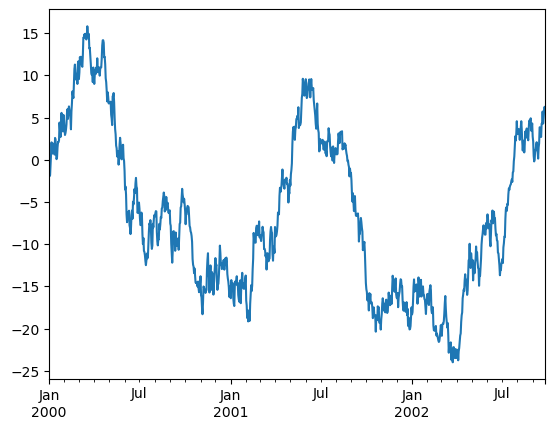

In [195]:
ts = pd.Series(np.random.randn(1000), index=pd.date_range('1/1/2000', periods=1000))
ts.cumsum().plot()

<Figure size 640x480 with 0 Axes>

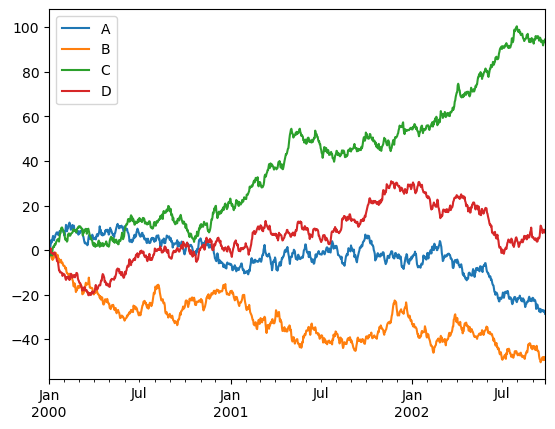

In [196]:
import matplotlib.pyplot as plt

pdf=pd.DataFrame(np.random.randn(1000, 4), index=ts.index,columns=['A', 'B', 'C', 'D'])
pdf = pdf.cumsum()
plt.figure(); pdf.plot(); plt.legend(loc='best')